# FleetLogix · Avance 2 — Análisis y optimización de queries SQL

**Proyecto Integrador M2 · Data Science** — Laura Garmendia

Con la base `fleetlogix` poblada (505.650 registros), en este avance:

1. **Ejecutamos y documentamos 8 de las 12 queries** propuestas: qué problema de negocio resuelve cada una, qué resultado da y qué se interpreta.
2. **Medimos su rendimiento** con `EXPLAIN ANALYZE` antes de optimizar.
3. **Creamos 5 índices** evaluados con datos, volvimos a medir y comparamos.

Las queries se escribieron y ejecutaron en **DBeaver** sobre PostgreSQL 16. Las versiones finales están en `2. Scripts/02_queries_analysis.sql` y `2. Scripts/03_optimization_indexes.sql`. Este notebook vuelve a ejecutar las queries para mostrar sus resultados junto al análisis.

| Nivel | Queries seleccionadas |
|---|---|
| Básicas | Q1, Q2, Q3 |
| Intermedias | Q4, Q5 y **Q8** (elegida entre Q6, Q7 y Q8) |
| Complejas | Q9 y **Q12** (elegida entre Q10, Q11 y Q12) |

## 0. Configuración

In [29]:
import warnings
from getpass import getpass
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import psycopg2
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=UserWarning)  # aviso de pandas al usar psycopg2 directo
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

conn = psycopg2.connect(host="localhost", database="fleetlogix", user="postgres", port=5432,
                        password=getpass("Contraseña de PostgreSQL: "))

def q(sql):
    "Ejecuta una consulta y devuelve el resultado como DataFrame."
    return pd.read_sql(sql, conn)

CAPTURAS = Path("..") / "3. Documentación" / "capturas_avance2"
def captura(nombre, ancho=900):
    "Muestra una captura de DBeaver (evidencia de EXPLAIN ANALYZE)."
    ruta = CAPTURAS / f"{nombre}.jpg"
    if ruta.exists():
        display(Image(filename=str(ruta), width=ancho))
    else:
        print(f"(captura pendiente: {ruta.name})")

## 1. Criterio de elección de las queries optativas

**Q8 (entre Q6, Q7 y Q8):** filtra la tabla más grande (`deliveries`, 400.000 filas) por fecha y analiza un problema operativo concreto: los retrasos.

**Q12 frente a Q10 (entre Q10, Q11 y Q12):** se eligió la Q12. La Q10 busca identificar a los conductores con mejor desempeño para incentivos, pero en estos datos sintéticos los viajes se asignan según la disponibilidad de cada conductor y su descanso mínimo, no según su desempeño. Por eso las diferencias entre conductores serían producto del azar. Además, el consumo de combustible depende principalmente del tipo de vehículo asignado, lo que impide comparar a los conductores en igualdad de condiciones. La Q12, en cambio, analiza patrones de entregas por hora y día que sí están presentes en los datos, y aporta información directa para planificar turnos y personal.

**Nota sobre las fechas:** los filtros "últimos N días" se calculan desde `CURRENT_DATE`, pero los datos llegan hasta la fecha de generación (15/10/2026). Son una foto de ese momento: una ventana de 60 días tomada el 28/10 contiene unos 47 días de datos.

## 2. Queries básicas

### Q1 · Vehículos por tipo
**Problema de negocio:** conocer la composición de la flota.
**Qué obtiene:** cuántos vehículos hay de cada tipo, de mayor a menor (`GROUP BY` + `COUNT`).

In [30]:
q('''
SELECT vehicle_type, COUNT(*) AS cantidad
FROM vehicles
GROUP BY vehicle_type
ORDER BY cantidad DESC''')

,vehicle_type,cantidad
0,Camión Mediano,63
1,Van,61
2,Camión Grande,60
3,Motocicleta,16


**Análisis:** la flota está repartida en partes casi iguales entre camiones grandes, medianos y vans (~30% cada uno), y las motocicletas son el 8%. Es una flota orientada a cargas medianas y grandes; las motos cubren solo rutas cortas.

### Q2 · Licencias próximas a vencer
**Problema de negocio:** prevenir problemas legales por licencias vencidas.
**Qué obtiene:** los conductores cuya licencia vence antes de hoy + 30 días, de la más urgente a la menos urgente.

In [31]:
q('''
SELECT first_name, last_name, license_number, license_expiry
FROM drivers
WHERE license_expiry < CURRENT_DATE + INTERVAL '30 days'
ORDER BY license_expiry''')

,first_name,last_name,license_number,license_expiry
0,Humberto,Hernández,1848574481,2026-09-15
1,Ángela,Hurtado,8152755025,2026-09-16
2,Yamile,Rangel,6833653567,2026-09-22
3,Juan,Castellanos,7345253768,2026-09-23
4,José,Díaz,1629384683,2026-09-25
5,Ana,Galindo,3559574211,2026-10-11
6,Stiven,García,1346877993,2026-10-14
7,José,Ochoa,7343544907,2026-10-14
8,Harold,Bautista,9645282662,2026-10-14
9,Patricia,Ibarra,9989466736,2026-10-15


**Análisis:** la query devuelve 23 conductores, pero la condición *"vence antes de hoy + 30 días"* también incluye las licencias **ya vencidas**. De los 23, **14 ya vencieron** y **9 vencen en los próximos 30 días**: son dos urgencias distintas (acción inmediata contra aviso preventivo).

Hoy el riesgo operativo es bajo: quedan unos 360 conductores disponibles para unos 140 viajes diarios. Pero vencen alrededor de 10 licencias por mes, así que sin un proceso de renovación el problema crecería. La query funciona como **alerta temprana**. Se propone una versión que clasifica cada licencia:

In [32]:
q('''
SELECT first_name, last_name, license_number, license_expiry,
       CASE WHEN license_expiry < CURRENT_DATE THEN 'Vencida' ELSE 'Por vencer' END AS estado_licencia
FROM drivers
WHERE license_expiry < CURRENT_DATE + INTERVAL '30 days'
ORDER BY license_expiry''')

,first_name,last_name,license_number,license_expiry,estado_licencia
0,Humberto,Hernández,1848574481,2026-09-15,Vencida
1,Ángela,Hurtado,8152755025,2026-09-16,Vencida
2,Yamile,Rangel,6833653567,2026-09-22,Vencida
3,Juan,Castellanos,7345253768,2026-09-23,Vencida
4,José,Díaz,1629384683,2026-09-25,Vencida
5,Ana,Galindo,3559574211,2026-10-11,Vencida
6,Stiven,García,1346877993,2026-10-14,Vencida
7,José,Ochoa,7343544907,2026-10-14,Vencida
8,Harold,Bautista,9645282662,2026-10-14,Vencida
9,Patricia,Ibarra,9989466736,2026-10-15,Vencida


### Q3 · Viajes por estado
**Problema de negocio:** monitorear las operaciones en curso.
**Qué obtiene:** cuántos viajes hay en cada estado.

In [33]:
q('''
SELECT status, COUNT(*) AS total_viajes
FROM trips
GROUP BY status''')

,status,total_viajes
0,completed,99981
1,in_progress,19


**Análisis:** 99.981 viajes completados y 19 en curso. Los 19 estaban en ruta en el momento en que se generaron los datos: el estado no se actualiza solo con el paso del tiempo.

## 3. Queries intermedias

### Q4 · Entregas por ciudad destino (últimos 2 meses)
**Problema de negocio:** identificar la demanda por ciudad para planificar recursos.
**Qué obtiene:** une 3 tablas (`routes`, `trips`, `deliveries`) y, para los viajes de los últimos 60 días, muestra por ciudad los viajes, las entregas y los kilos entregados.

In [34]:
q('''
SELECT r.destination_city,
       COUNT(DISTINCT t.trip_id) AS total_viajes,
       COUNT(d.delivery_id) AS total_entregas,
       SUM(d.package_weight_kg) AS peso_total_kg
FROM routes r
INNER JOIN trips t ON r.route_id = t.route_id
INNER JOIN deliveries d ON t.trip_id = d.trip_id
WHERE t.departure_datetime >= CURRENT_DATE - INTERVAL '60 days'
GROUP BY r.destination_city
ORDER BY total_entregas DESC''')

,destination_city,total_viajes,total_entregas,peso_total_kg
0,Bogotá,1420,5666,2913539.64
1,Cartagena,1159,4718,2062611.23
2,Barranquilla,1164,4631,1990522.71
3,Medellín,1066,4245,2161556.72
4,Cali,1041,4167,2109580.32


**Verificación:** como cada viaje tiene una sola ciudad destino, la suma de viajes por ciudad debe coincidir con el total del período:

In [35]:
q('''
SELECT COUNT(*) AS total_viajes
FROM trips
WHERE departure_datetime >= CURRENT_DATE - INTERVAL '60 days' ''')

,total_viajes
0,5850


**Análisis:** 6.936 viajes en el período (verificado con la segunda query). **Bogotá concentra la mayor demanda**, en línea con que es la ciudad con más rutas (3 por cada par de ciudades que la incluye). Las otras cuatro ciudades tienen una demanda similar entre sí.

### Q5 · Viajes por conductor activo
**Problema de negocio:** evaluar la carga de trabajo por conductor.
**Qué obtiene:** para cada conductor activo, sus viajes totales y completados (`LEFT JOIN` + `GROUP BY` + `HAVING`).

In [36]:
q('''
SELECT d.driver_id,
       d.first_name || ' ' || d.last_name AS nombre_completo,
       d.license_expiry,
       COUNT(t.trip_id) AS viajes_totales,
       SUM(CASE WHEN t.status = 'completed' THEN 1 ELSE 0 END) AS viajes_completados
FROM drivers d
LEFT JOIN trips t ON d.driver_id = t.driver_id
WHERE d.status = 'active'
GROUP BY d.driver_id, d.first_name, d.last_name, d.license_expiry
HAVING COUNT(t.trip_id) > 0
ORDER BY viajes_completados DESC''')

,driver_id,nombre_completo,license_expiry,viajes_totales,viajes_completados
0,255,Ocampo Pinto,2029-06-15,357,357
1,224,César González,2026-11-28,356,356
2,318,Antonio Mejía,2027-03-25,352,351
3,196,Nelson Rangel,2026-11-09,350,350
4,373,Jairo Sánchez,2029-09-11,349,349
...,...,...,...,...,...
372,219,Lucía Narváez,2028-02-04,11,11
373,182,Javier Melo,2027-08-06,10,10
374,223,Andrés Ramírez,2029-04-22,9,9
375,230,Ever Vanegas,2029-06-18,6,6


**Análisis:** los 377 conductores activos tienen viajes (el `HAVING` no descarta a nadie). La diferencia es muy grande: de **más de 350 viajes a menos de 10**. Para entender la causa, se revisan los 10 con menos viajes:

In [37]:
q('''
SELECT d.first_name || ' ' || d.last_name AS nombre_completo,
       d.hire_date, d.license_expiry,
       COUNT(t.trip_id) AS viajes_totales
FROM drivers d
LEFT JOIN trips t ON d.driver_id = t.driver_id
WHERE d.status = 'active'
GROUP BY d.driver_id, d.first_name, d.last_name, d.hire_date, d.license_expiry
ORDER BY viajes_totales ASC
LIMIT 10''')

,nombre_completo,hire_date,license_expiry,viajes_totales
0,Uriel Ríos,2026-10-03,2028-12-15,5
1,Ever Vanegas,2026-09-24,2029-06-18,6
2,Andrés Ramírez,2026-09-17,2029-04-22,9
3,Javier Melo,2026-09-26,2027-08-06,10
4,Lucía Narváez,2026-09-13,2028-02-04,11
5,Laura Buitrago,2026-09-18,2029-01-08,12
6,José Espinosa,2026-09-10,2029-07-31,13
7,Martha Molina,2026-08-30,2029-07-24,14
8,Alejandra Torres,2026-09-06,2029-09-23,15
9,Sebastián Cano,2026-08-17,2027-08-29,20


Todos fueron **contratados entre agosto y octubre de 2026** y tienen la licencia vigente. La diferencia se explica por **antigüedad**, no por una carga mal repartida. Comparar viajes totales entre conductores con distinta antigüedad es engañoso; para evaluar la carga real habría que medir **viajes por mes trabajado**.

### Q8 · Entregas retrasadas por día de la semana
**Problema de negocio:** identificar patrones de retraso para mejorar la planificación.
**Qué obtiene:** para las entregas de los últimos 90 días, por día de la semana: total, cantidad y porcentaje con más de 30 minutos de retraso, y la diferencia promedio en minutos. Usa `EXTRACT(DOW)`, `EXTRACT(EPOCH)` y `COUNT(CASE WHEN ...)` (un "contar si").

In [38]:
q('''
SELECT TO_CHAR(d.scheduled_datetime, 'Day') AS dia_semana,
       EXTRACT(DOW FROM d.scheduled_datetime) AS num_dia,
       COUNT(*) AS total_entregas,
       COUNT(CASE WHEN d.delivered_datetime > d.scheduled_datetime + INTERVAL '30 minutes' THEN 1 END) AS entregas_retrasadas,
       ROUND(100.0 * COUNT(CASE WHEN d.delivered_datetime > d.scheduled_datetime + INTERVAL '30 minutes' THEN 1 END) / COUNT(*), 2) AS porcentaje_retrasos,
       AVG(EXTRACT(EPOCH FROM (d.delivered_datetime - d.scheduled_datetime)) / 60) AS minutos_promedio_diferencia
FROM deliveries d
WHERE d.delivery_status = 'delivered'
  AND d.scheduled_datetime >= CURRENT_DATE - INTERVAL '90 days'
GROUP BY dia_semana, num_dia
ORDER BY num_dia''')

,dia_semana,num_dia,total_entregas,entregas_retrasadas,porcentaje_retrasos,minutos_promedio_diferencia
0,Sunday,0.0,3469,416,11.99,14.360911
1,Monday,1.0,4673,686,14.68,18.000214
2,Tuesday,2.0,6988,965,13.81,17.091872
3,Wednesday,3.0,6658,784,11.78,15.155903
4,Thursday,4.0,7037,889,12.63,16.134574
5,Friday,5.0,7209,1010,14.01,17.955472
6,Saturday,6.0,5995,921,15.36,18.532444


**Análisis:** no hay un día crítico. Todos los días, entre el 12% y el 15% de las entregas llega con más de 30 minutos de retraso, con una diferencia promedio de 15 a 18 minutos. El retraso es **estructural**, no de un día puntual: conviene atacar causas generales (tránsito, tiempos de ruta, planificación de paradas) más que reforzar un día en particular.

## 4. Queries complejas

### Q9 · Costo de mantenimiento por kilómetro
**Problema de negocio:** evaluar el costo-beneficio de cada tipo de vehículo.
**Qué obtiene:** una CTE calcula viajes, km y costos de mantenimiento por vehículo; la consulta principal agrupa por tipo y calcula el costo por km.

#### Verificación de los totales
Al ejecutar la versión inicial, el costo total de mantenimiento resultó desproporcionado. Se contrastó con la suma directa de la tabla:

In [39]:
q('''
SELECT COUNT(*) AS cantidad_mantenimientos, SUM(cost) AS costo_total_real
FROM maintenance''')

,cantidad_mantenimientos,costo_total_real
0,5000,1.941943e+09


In [40]:
q9_inicial = q('''
WITH vehicle_metrics AS (
    SELECT v.vehicle_id, v.vehicle_type, v.license_plate,
           COUNT(DISTINCT t.trip_id) AS total_viajes,
           SUM(r.distance_km) AS km_totales,
           SUM(m.cost) AS costo_mantenimiento_total,
           COUNT(DISTINCT m.maintenance_id) AS cantidad_mantenimientos
    FROM vehicles v
    LEFT JOIN trips t ON v.vehicle_id = t.vehicle_id
    LEFT JOIN routes r ON t.route_id = r.route_id
    LEFT JOIN maintenance m ON v.vehicle_id = m.vehicle_id
    WHERE t.status = 'completed'
    GROUP BY v.vehicle_id, v.vehicle_type, v.license_plate
)
SELECT vehicle_type, COUNT(vehicle_id) AS cantidad_vehiculos, SUM(total_viajes) AS viajes_totales,
       SUM(km_totales) AS kilometros_totales, SUM(costo_mantenimiento_total) AS costo_total_mantenimiento,
       ROUND(SUM(costo_mantenimiento_total) / NULLIF(SUM(km_totales), 0), 2) AS costo_por_km,
       ROUND(AVG(costo_mantenimiento_total / NULLIF(cantidad_mantenimientos, 0)), 2) AS costo_promedio_por_mantenimiento
FROM vehicle_metrics
WHERE km_totales > 0 AND costo_mantenimiento_total > 0
GROUP BY vehicle_type
ORDER BY costo_por_km DESC''')
print(f"Costo total según la versión inicial de la Q9: ${q9_inicial['costo_total_mantenimiento'].sum():,.0f}")
q9_inicial

Costo total según la versión inicial de la Q9: $1,179,313,626,296


,vehicle_type,cantidad_vehiculos,viajes_totales,kilometros_totales,costo_total_mantenimiento,costo_por_km,costo_promedio_por_mantenimiento
0,Motocicleta,16,4095.0,7.296710e+06,7.004204e+09,959.91,2.971048e+07
1,Camión Grande,60,31842.0,7.371939e+08,4.969673e+11,674.13,2.700237e+08
2,Camión Mediano,63,33481.0,7.931162e+08,4.032117e+11,508.39,2.013566e+08
3,Van,61,30563.0,5.862485e+08,2.721304e+11,464.19,1.552255e+08


El costo real es **$1.941.943.140** (unos $388.000 por mantenimiento), pero la versión inicial de la Q9 suma más de **un billón** de pesos: unas **600 veces** el valor real.

**Causa: multiplicación de filas (*fan-out*).** La CTE une un vehículo con sus viajes **y** con sus mantenimientos en el mismo paso. Un vehículo con 500 viajes y 25 mantenimientos genera 500 × 25 = 12.500 filas combinadas: cada costo se suma 500 veces y cada kilómetro, 25 veces. El costo por km queda distorsionado y la query procesa millones de filas innecesarias.

**Ajuste:** agregar viajes y mantenimientos **por separado** (una fila por vehículo en cada CTE) y recién después unirlos.

In [41]:
q('''
WITH km_por_vehiculo AS (
    SELECT t.vehicle_id, COUNT(*) AS total_viajes, SUM(r.distance_km) AS km_totales
    FROM trips t
    JOIN routes r ON t.route_id = r.route_id
    WHERE t.status = 'completed'
    GROUP BY t.vehicle_id
),
mant_por_vehiculo AS (
    SELECT vehicle_id, COUNT(*) AS cantidad_mantenimientos, SUM(cost) AS costo_mantenimiento_total
    FROM maintenance
    GROUP BY vehicle_id
)
SELECT v.vehicle_type, COUNT(*) AS cantidad_vehiculos, SUM(k.total_viajes) AS viajes_totales,
       SUM(k.km_totales) AS kilometros_totales, SUM(m.costo_mantenimiento_total) AS costo_total_mantenimiento,
       ROUND(SUM(m.costo_mantenimiento_total) / NULLIF(SUM(k.km_totales), 0), 2) AS costo_por_km,
       ROUND(SUM(m.costo_mantenimiento_total) / SUM(m.cantidad_mantenimientos), 2) AS costo_promedio_por_mantenimiento
FROM vehicles v
JOIN km_por_vehiculo k   ON v.vehicle_id = k.vehicle_id
JOIN mant_por_vehiculo m ON v.vehicle_id = m.vehicle_id
GROUP BY v.vehicle_type
ORDER BY costo_por_km DESC''')

,vehicle_type,cantidad_vehiculos,viajes_totales,kilometros_totales,costo_total_mantenimiento,costo_por_km,costo_promedio_por_mantenimiento
0,Motocicleta,16,4095.0,497739.81,2.402892e+07,48.28,116081.74
1,Camión Grande,60,31842.0,24169757.82,8.112844e+08,33.57,508961.36
2,Camión Mediano,63,33481.0,24951390.55,6.335928e+08,25.39,378943.03
3,Van,61,30563.0,20302335.83,4.730371e+08,23.30,309781.96


**Análisis (versión ajustada):** la suma de `costo_total_mantenimiento` coincide con el costo real.
- La **motocicleta es la más cara por kilómetro** (~48 COP/km), aunque tiene el servicio **más barato** (~116.000): hace rutas cortas y cada servicio se reparte entre pocos kilómetros.
- La **van es la más eficiente** (~23 COP/km).
- El **camión grande** tiene el servicio más caro (~509.000), pero lo compensa con muchos kilómetros.

El vehículo con el servicio más barato no es necesariamente el más económico de mantener.

### Q12 · Pivot de entregas por hora y día de la semana
**Problema de negocio:** optimizar horarios de operación y personal.
**Qué obtiene:** una tabla de doble entrada, con las horas (6 a 22) en las filas y los días en las columnas. La CTE devuelve una fila por cada combinación de día y hora (formato largo), y cada `SUM(CASE WHEN dia_semana = X ...)` lleva un día a su propia columna (formato ancho). Es la técnica **PIVOT** hecha con `CASE`.

In [42]:
pivot = q('''
WITH entregas_por_hora_dia AS (
    SELECT EXTRACT(DOW FROM scheduled_datetime) AS dia_semana,
           EXTRACT(HOUR FROM scheduled_datetime) AS hora,
           COUNT(*) AS cantidad_entregas
    FROM deliveries
    WHERE scheduled_datetime >= CURRENT_DATE - INTERVAL '60 days'
    GROUP BY EXTRACT(DOW FROM scheduled_datetime), EXTRACT(HOUR FROM scheduled_datetime)
)
SELECT hora,
       SUM(CASE WHEN dia_semana = 0 THEN cantidad_entregas ELSE 0 END) AS domingo,
       SUM(CASE WHEN dia_semana = 1 THEN cantidad_entregas ELSE 0 END) AS lunes,
       SUM(CASE WHEN dia_semana = 2 THEN cantidad_entregas ELSE 0 END) AS martes,
       SUM(CASE WHEN dia_semana = 3 THEN cantidad_entregas ELSE 0 END) AS miercoles,
       SUM(CASE WHEN dia_semana = 4 THEN cantidad_entregas ELSE 0 END) AS jueves,
       SUM(CASE WHEN dia_semana = 5 THEN cantidad_entregas ELSE 0 END) AS viernes,
       SUM(CASE WHEN dia_semana = 6 THEN cantidad_entregas ELSE 0 END) AS sabado,
       SUM(cantidad_entregas) AS total_semana
FROM entregas_por_hora_dia
WHERE hora BETWEEN 6 AND 22
GROUP BY hora
ORDER BY hora''')
pivot.astype(int).set_index("hora")

,domingo,lunes,martes,miercoles,jueves,viernes,sabado,total_semana
hora,,,,,,,,
6,98,62,146,178,156,121,141,902
7,81,61,147,139,136,112,140,816
8,87,73,127,152,136,124,144,843
9,87,77,132,149,131,115,155,846
10,96,82,140,135,137,130,171,891
11,93,91,156,125,121,124,147,857
12,76,102,150,135,126,118,120,827
13,70,122,130,131,110,119,109,791
14,75,130,149,137,113,141,112,857


**Análisis:** de martes a sábado las entregas se reparten de forma pareja. El domingo y el lunes muestran patrones opuestos, por un **efecto de arrastre**: las entregas se hacen varias horas después de la salida del viaje.
- **El domingo** concentra entregas en las primeras horas (viajes despachados el sábado que llegan a destino) y decrece durante el día, porque ese día casi no se despacha.
- **El lunes** arranca bajo (pocos viajes salieron el domingo) y crece a medida que llegan los despachos del día.
- Las bajas de 7 a 8 h y de 12 a 14 h reflejan, desplazados en el tiempo, los valles en los horarios de salida.

**Implicancia operativa:** aunque el domingo casi no se despacha, se necesita personal de reparto el domingo a la mañana para completar las entregas en curso; el lunes, la demanda de personal crece a lo largo del día.

## 5. Optimización con índices

### 5.1 Método
1. Cada query se midió con `EXPLAIN ANALYZE` en DBeaver **antes** de crear índices.
2. Se evaluaron los 5 índices propuestos y se armó el set final.
3. Se actualizaron las estadísticas (`VACUUM ANALYZE`) y se volvió a medir **después**.

Cada medición se ejecutó **dos veces** y se registró la segunda. Se compara el **Execution Time** (el tiempo de hacer el trabajo); el *Planning Time* (el tiempo de decidir cómo hacerlo) es de décimas de milisegundo. Las diferencias menores a 1 ms se consideran **ruido** de medición.

### 5.2 Evaluación de los índices propuestos

| Índice propuesto | ¿Se usa? | Decisión |
|---|---|---|
| `idx_trips_composite_joins` | Sí (Q9) | Se conserva |
| `idx_maintenance_vehicle_cost` | Sí (Q9) | Se conserva |
| `idx_deliveries_scheduled_datetime` (parcial, solo `'delivered'`) | No en la Q12: no filtra por estado | Se reemplaza |
| `idx_drivers_status_license` | No: tabla de 400 filas | Se descarta |
| `idx_routes_metrics` | No: tabla de 50 filas | Se descarta |

### 5.3 Set final: 2 de los propuestos + 3 nuevos

| # | Índice | Tipo | Queries |
|---|---|---|---|
| 1 | `idx_deliveries_scheduled` → `deliveries(scheduled_datetime) INCLUDE (delivered_datetime, delivery_status)` | Cubriente (nuevo) | Q8, Q12 |
| 2 | `idx_deliveries_trip_id` → `deliveries(trip_id)` | Clave foránea (nuevo) | Q4 |
| 3 | `idx_trips_status` → `trips(status)` | Simple (nuevo) | Q3 |
| 4 | `idx_trips_composite_joins` → `trips(vehicle_id, driver_id, route_id, departure_datetime) WHERE status = 'completed'` | Compuesto y parcial (propuesto) | Q9 |
| 5 | `idx_maintenance_vehicle_cost` → `maintenance(vehicle_id, cost)` | Compuesto (propuesto) | Q9 |

- **Índice cubriente:** con `INCLUDE`, el índice guarda las columnas que la query necesita, y PostgreSQL responde sin abrir la tabla (`Index Only Scan`).
- **Índice parcial:** con `WHERE`, solo indexa las filas que cumplen la condición.

**Ajuste de configuración:** `ALTER DATABASE fleetlogix SET random_page_cost = 1.1`. El valor por defecto (4) supone discos rígidos, donde el acceso aleatorio es lento; en un SSD es casi tan rápido como el secuencial. Sin este ajuste, la Q4 no usaba el índice 2.

Los índices ya fueron creados en DBeaver (`03_optimization_indexes.sql`). Se verifican:

In [43]:
q('''
SELECT tablename, indexname, indexdef
FROM pg_indexes
WHERE schemaname = 'public' AND indexname LIKE 'idx_%'
ORDER BY tablename, indexname''')

,tablename,indexname,indexdef
0,deliveries,idx_deliveries_scheduled,CREATE INDEX idx_deliveries_scheduled ON publi...
1,deliveries,idx_deliveries_status,CREATE INDEX idx_deliveries_status ON public.d...
2,deliveries,idx_deliveries_trip_id,CREATE INDEX idx_deliveries_trip_id ON public....
3,maintenance,idx_maintenance_vehicle_cost,CREATE INDEX idx_maintenance_vehicle_cost ON p...
4,trips,idx_trips_composite_joins,CREATE INDEX idx_trips_composite_joins ON publ...
5,trips,idx_trips_departure,CREATE INDEX idx_trips_departure ON public.tri...
6,trips,idx_trips_status,CREATE INDEX idx_trips_status ON public.trips ...
7,vehicles,idx_vehicles_status,CREATE INDEX idx_vehicles_status ON public.veh...


### 5.4 Resultados: antes y después

Tiempos medidos en DBeaver (Execution Time, en ms):

In [44]:
tiempos = pd.DataFrame([
    ("Q1",           0.219,   0.161, "Seq Scan (tabla de 200 filas)"),
    ("Q2",           0.125,   0.156, "Seq Scan (tabla de 400 filas)"),
    ("Q3",          22.026,  15.822, "Index Only Scan idx_trips_status"),
    ("Q4",          37.170,  33.841, "Index Scan idx_deliveries_trip_id"),
    ("Q5",          36.743,  37.707, "Seq Scan (necesita todos los viajes)"),
    ("Q8",          75.841,  43.264, "Index Only Scan idx_deliveries_scheduled"),
    ("Q9 inicial",  801.861, 479.250, "Más rápida, pero con totales sobrestimados"),
    ("Q9 ajustada", 38.274,  17.481, "Index Only Scan (índices 4 y 5)"),
    ("Q12",         38.530,  22.334, "Index Only Scan idx_deliveries_scheduled"),
], columns=["query", "antes_ms", "despues_ms", "plan_despues"])
tiempos["mejora_%"] = ((1 - tiempos["despues_ms"] / tiempos["antes_ms"]) * 100).round(0)
tiempos.loc[tiempos["query"].isin(["Q1", "Q2", "Q5"]), "mejora_%"] = None  # ruido o sin cambio
tiempos

,query,antes_ms,despues_ms,plan_despues,mejora_%
0,Q1,0.219,0.161,Seq Scan (tabla de 200 filas),NaN
1,Q2,0.125,0.156,Seq Scan (tabla de 400 filas),NaN
2,Q3,22.026,15.822,Index Only Scan idx_trips_status,28.0
3,Q4,37.170,33.841,Index Scan idx_deliveries_trip_id,9.0
4,Q5,36.743,37.707,Seq Scan (necesita todos los viajes),NaN
5,Q8,75.841,43.264,Index Only Scan idx_deliveries_scheduled,43.0
6,Q9 inicial,801.861,479.250,"Más rápida, pero con totales sobrestimados",40.0
7,Q9 ajustada,38.274,17.481,Index Only Scan (índices 4 y 5),54.0
8,Q12,38.530,22.334,Index Only Scan idx_deliveries_scheduled,42.0


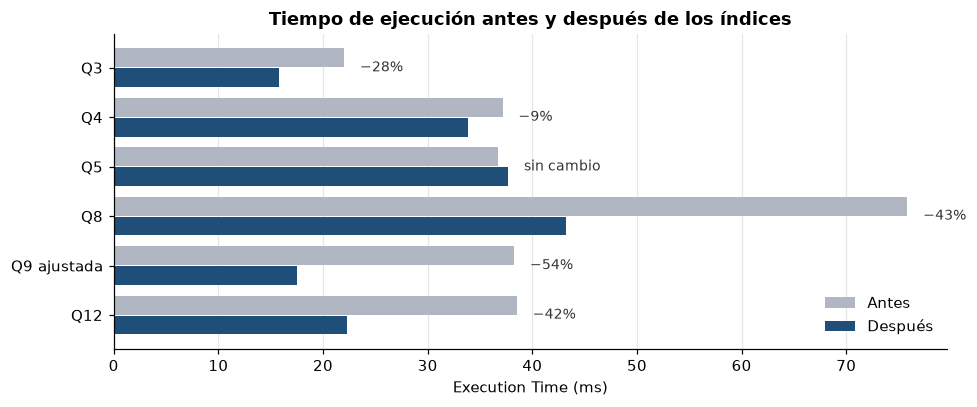

In [45]:
# Queries con trabajo real (se excluyen Q1 y Q2, que ya eran instantáneas, y la versión inicial de la Q9, por sus totales sobrestimados)
g = tiempos[tiempos["query"].isin(["Q3", "Q4", "Q5", "Q8", "Q9 ajustada", "Q12"])].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 3.8), dpi=110)
y = range(len(g))
ax.barh([i - 0.2 for i in y], g["antes_ms"], height=0.38, color="#B0B7C3", label="Antes")
ax.barh([i + 0.2 for i in y], g["despues_ms"], height=0.38, color="#1F4E79", label="Después")
for i, r in g.iterrows():
    etiqueta = f"−{r['mejora_%']:.0f}%" if pd.notna(r["mejora_%"]) else "sin cambio"
    ax.annotate(etiqueta, (max(r["antes_ms"], r["despues_ms"]) + 1.5, i), va="center", fontsize=9, color="#333")
ax.set_yticks(list(y)); ax.set_yticklabels(g["query"]); ax.invert_yaxis()
ax.set_xlabel("Execution Time (ms)"); ax.set_title("Tiempo de ejecución antes y después de los índices", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", color="#E6E6E6"); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

**Lectura de los resultados:**
- **Las que más ganan son las que filtran `deliveries` por fecha:** Q8 (43%) y Q12 (42%) pasan a responder solo con el índice cubriente.
- **Q9 ajustada (54%)** y **Q3 (28%)** también pasan a `Index Only Scan`.
- **Q4 (9%):** el plan cambió a `Index Scan using idx_deliveries_trip_id`, lo que confirma que el índice es adecuado, pero la mayor parte del tiempo está en la agregación (`COUNT(DISTINCT)`, `SUM`), que el índice no acelera.
- **Q1 y Q2:** tablas de 200 y 400 filas, ya instantáneas; las variaciones son ruido.
- **Q5:** necesita leer todos los viajes para contarlos por conductor; ningún índice evita esa lectura.

### 5.5 La lección de la Q9

In [46]:
q9 = tiempos.set_index("query").loc[["Q9 inicial", "Q9 ajustada"]]
print(f"Q9 inicial, antes de índices:      {q9.loc['Q9 inicial', 'antes_ms']:8.1f} ms  (totales sobrestimados)")
print(f"Q9 inicial, después de índices:    {q9.loc['Q9 inicial', 'despues_ms']:8.1f} ms  (siguen sobrestimados)")
print(f"Q9 ajustada, después de índices:   {q9.loc['Q9 ajustada', 'despues_ms']:8.1f} ms  (resultado real)")
print(f"Mejora total (lógica + índices):   {(1 - q9.loc['Q9 ajustada', 'despues_ms'] / q9.loc['Q9 inicial', 'antes_ms']) * 100:8.0f} %")

Q9 inicial, antes de índices:         801.9 ms  (totales sobrestimados)
Q9 inicial, después de índices:       479.2 ms  (siguen sobrestimados)
Q9 ajustada, después de índices:       17.5 ms  (resultado real)
Mejora total (lógica + índices):         98 %


Con índices, la versión inicial de la Q9 bajó de 802 a 479 ms, pero **siguió devolviendo totales sobrestimados**. La versión ajustada con índices tarda 17 ms y da el resultado real: **un índice acelera una consulta, pero no cambia lo que calcula**. Antes de optimizar, hay que verificar la lógica.

## 6. Evidencia: capturas de `EXPLAIN ANALYZE` en DBeaver

Cada par muestra el plan y el tiempo antes y después de los índices.

**Q3**

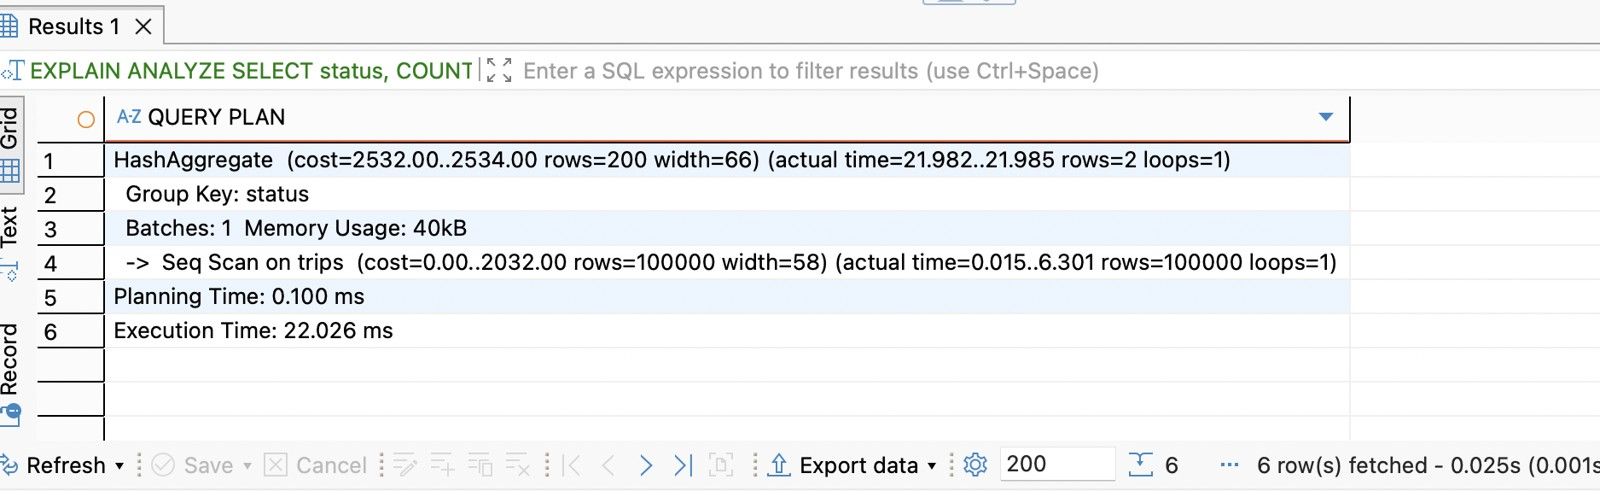

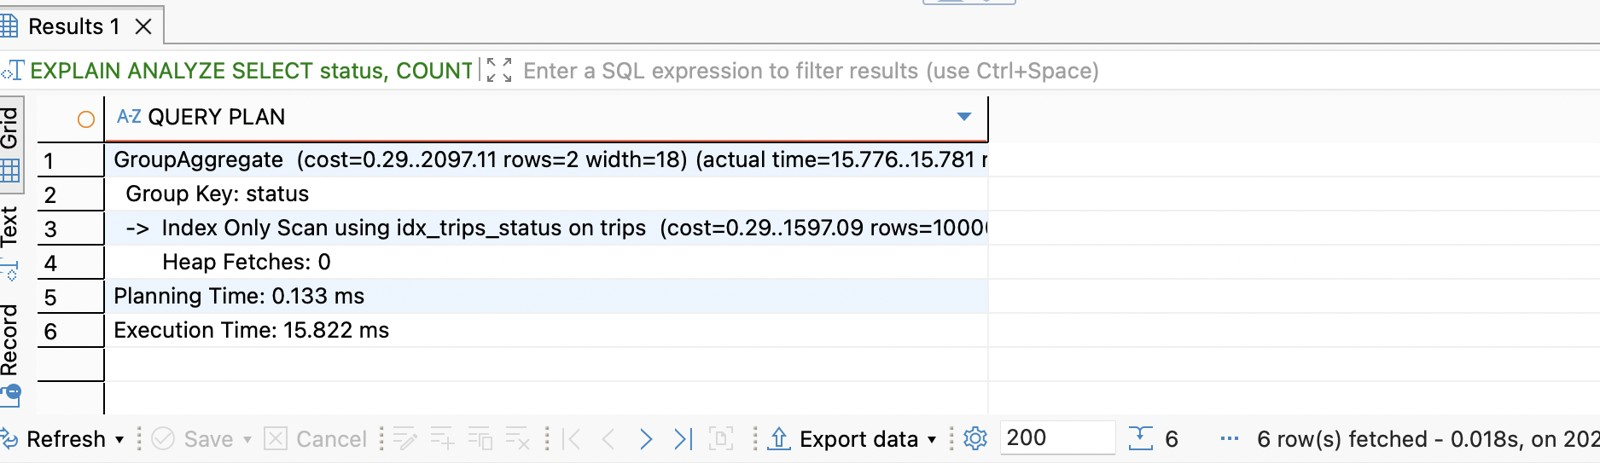

In [47]:
captura("Q3_antes"); captura("Q3_despues")

**Q4**

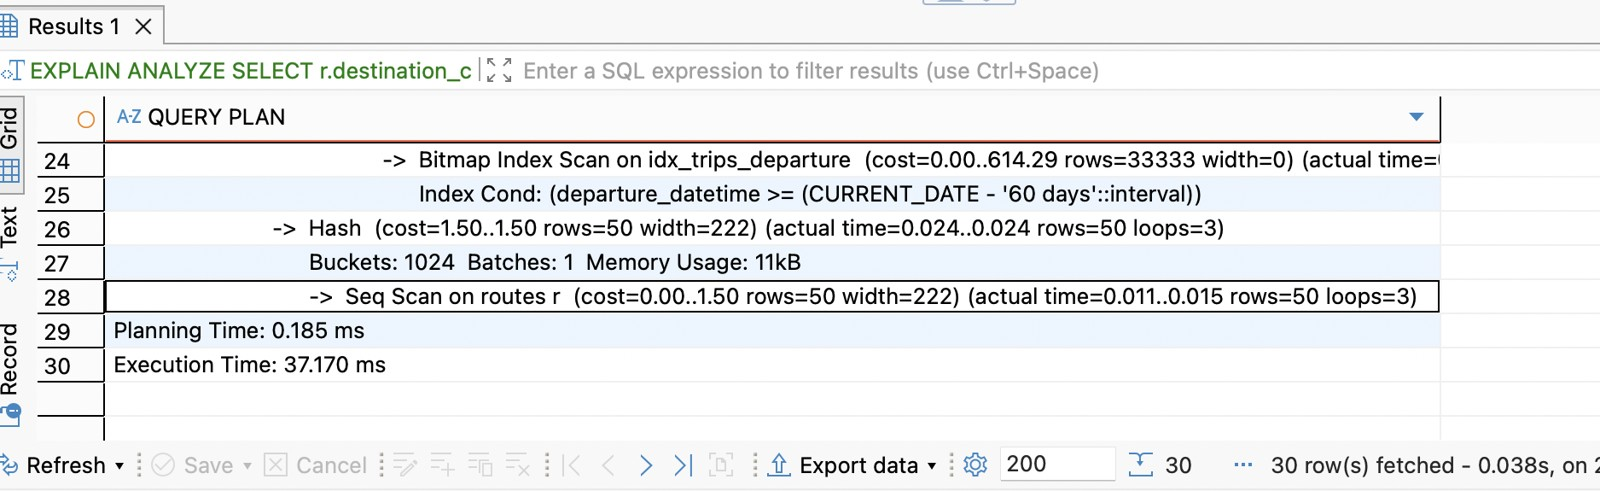

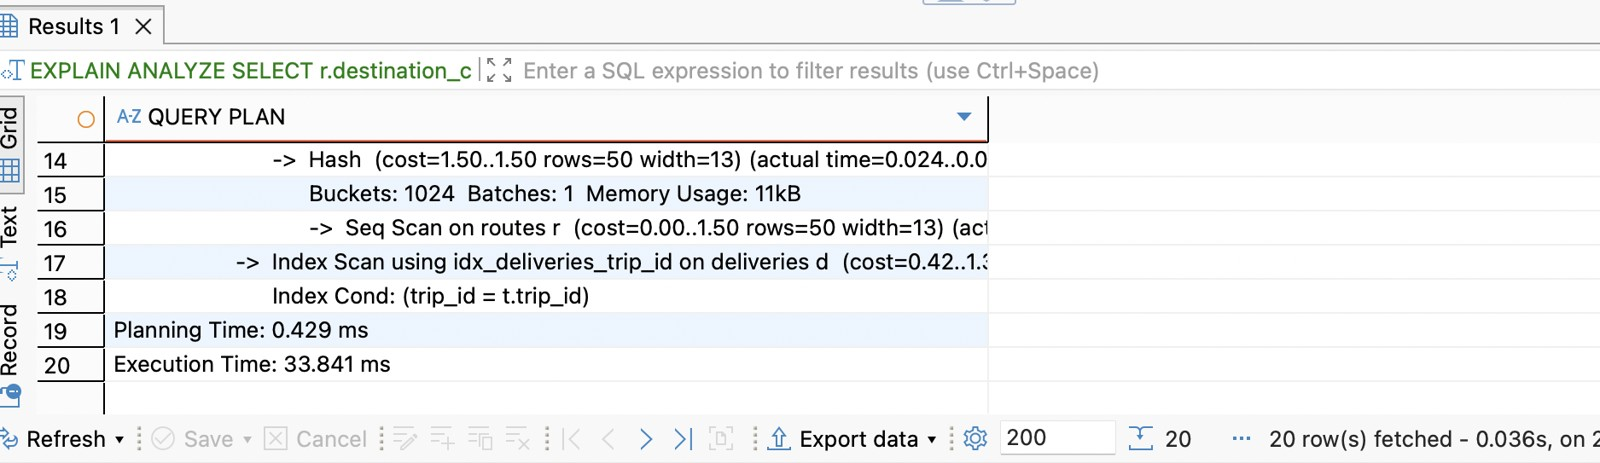

In [48]:
captura("Q4_antes"); captura("Q4_despues")

**Q8**

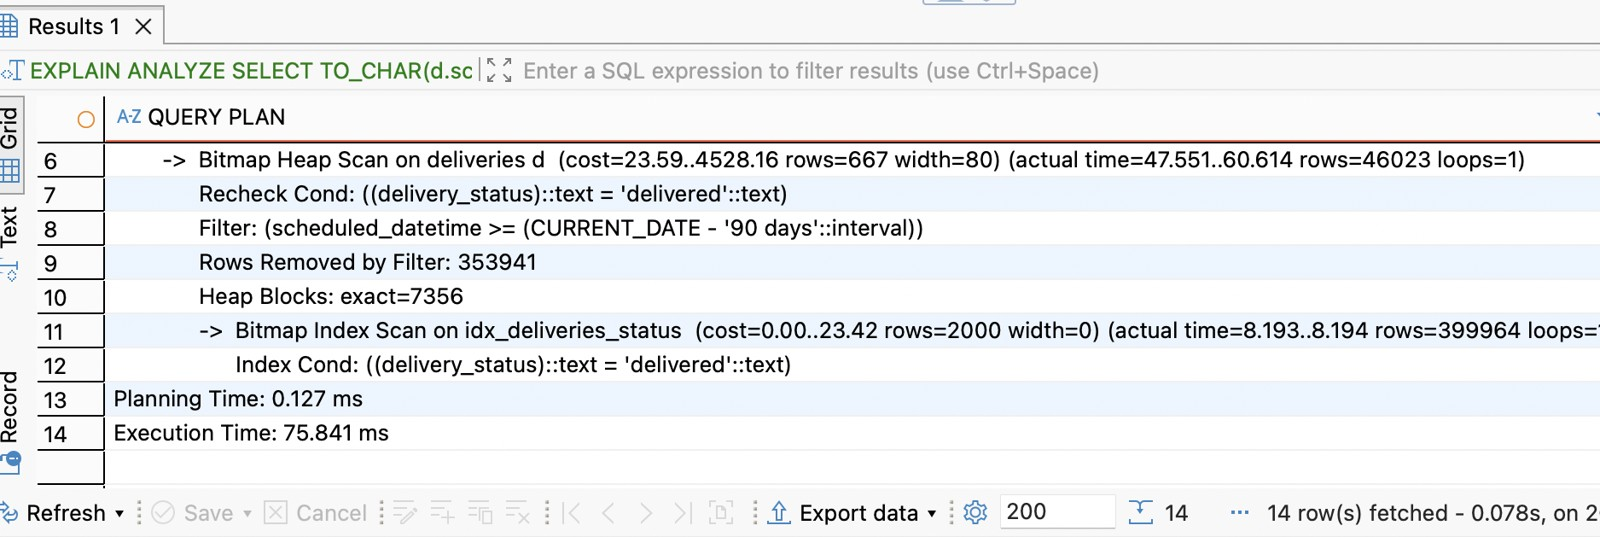

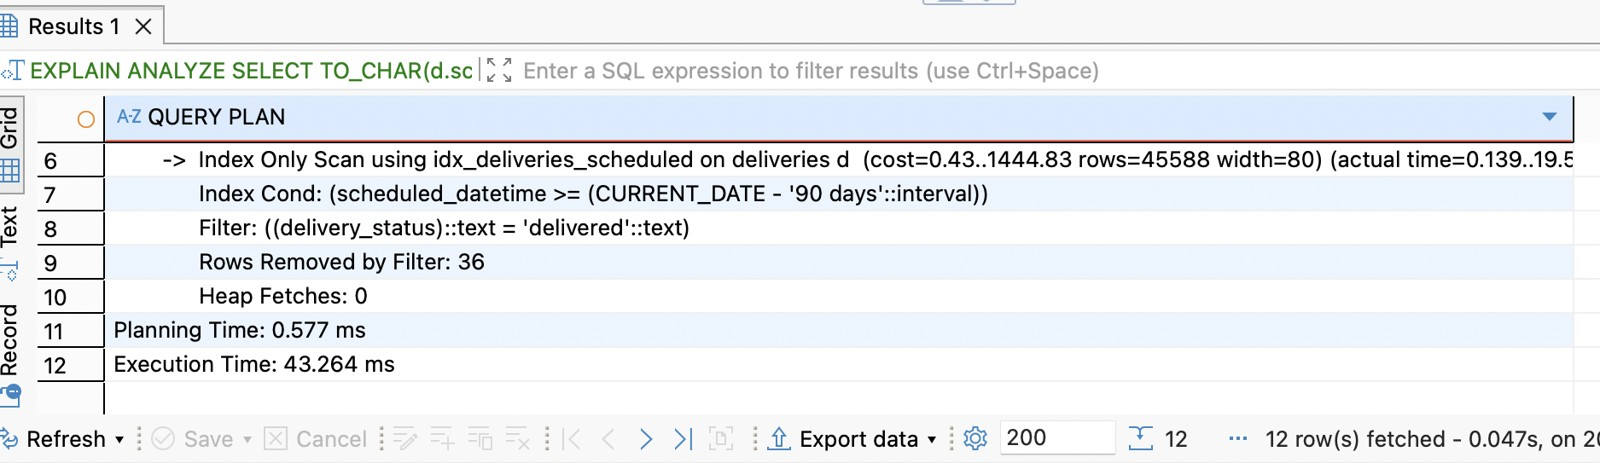

In [49]:
captura("Q8_antes"); captura("Q8_despues")

**Q9 versión inicial**

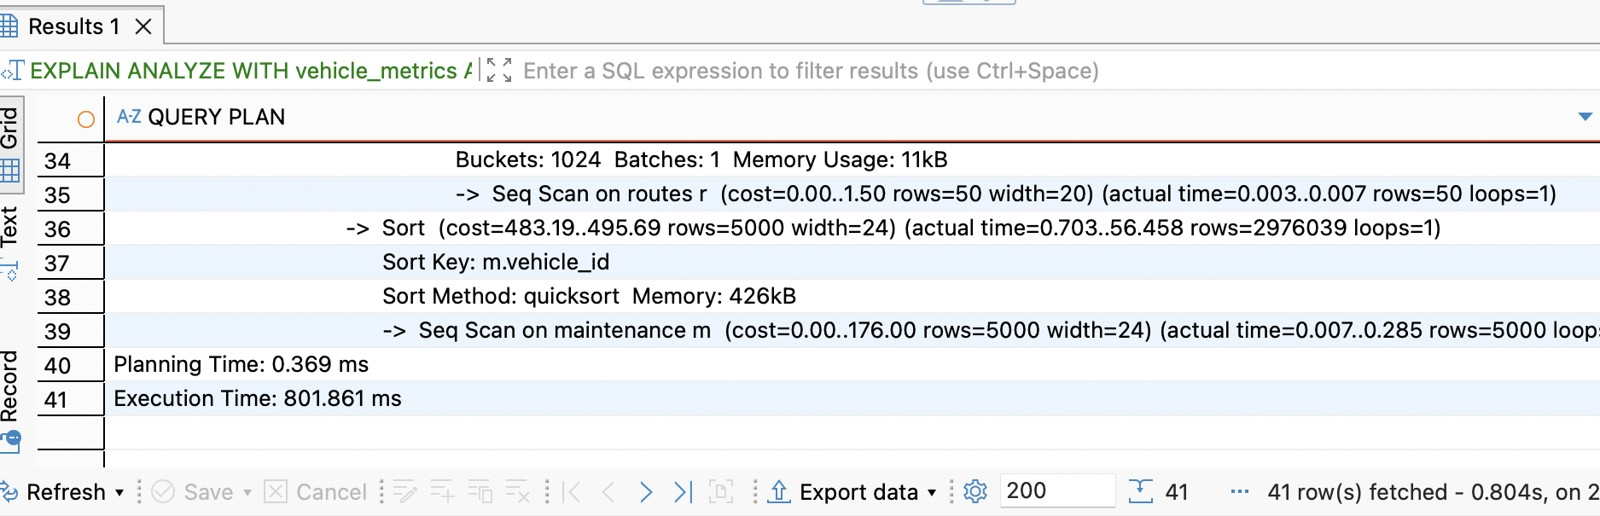

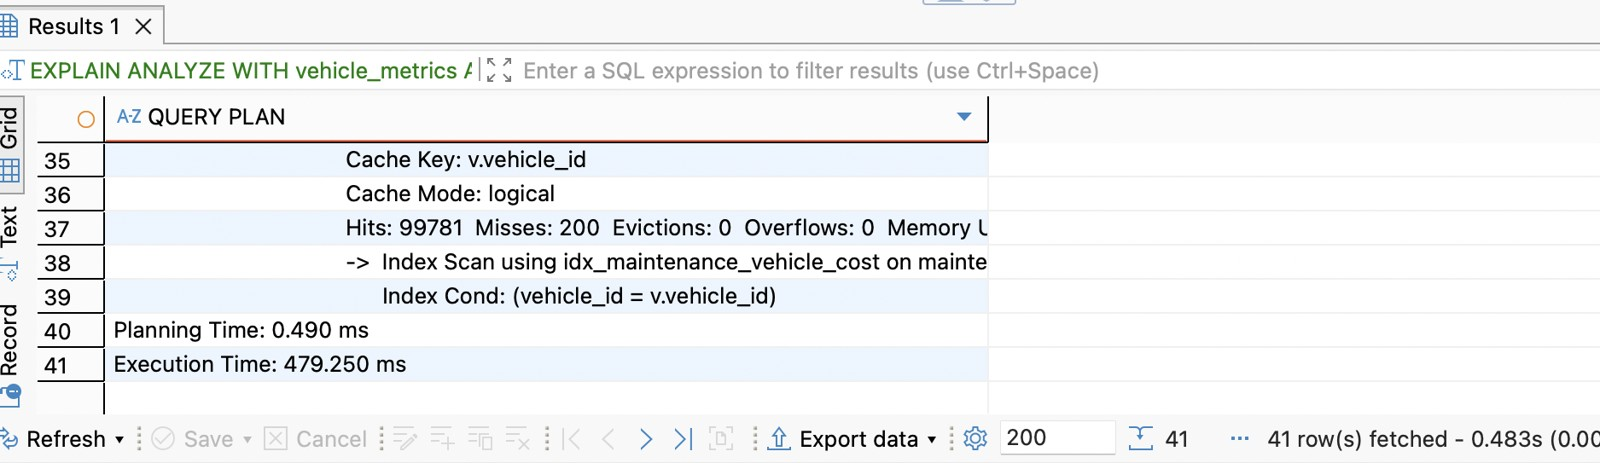

In [50]:
captura("Q9_inicial_antes"); captura("Q9_inicial_despues")

**Q9 versión ajustada**

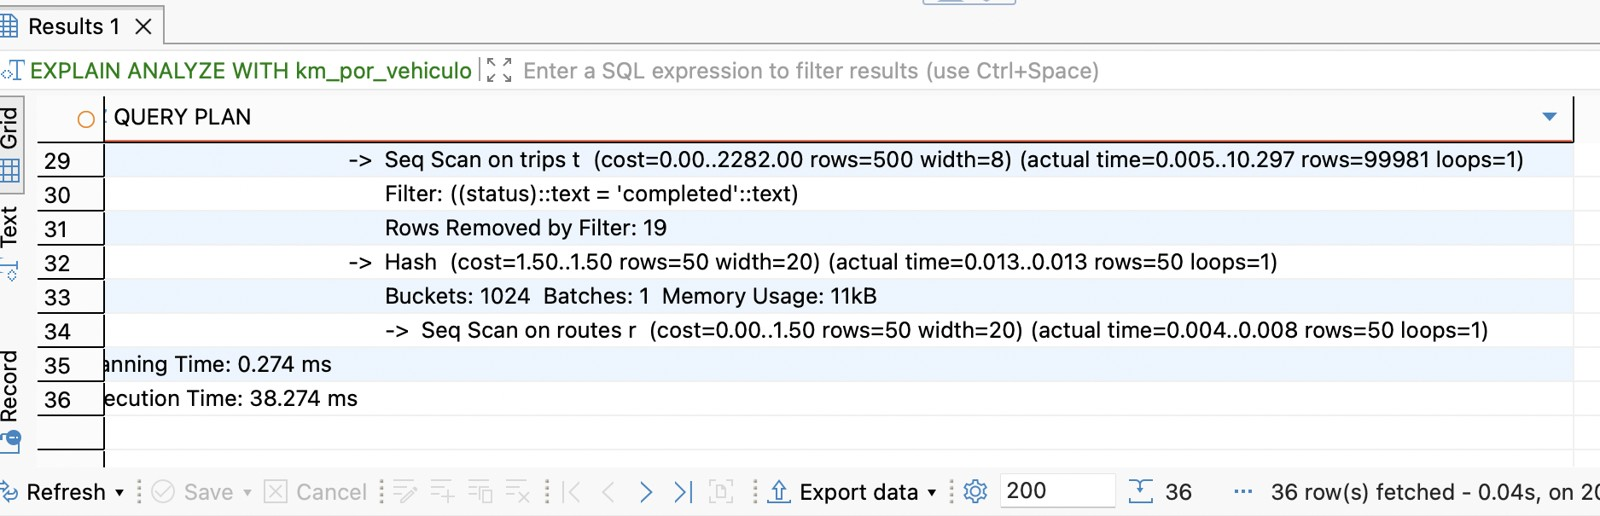

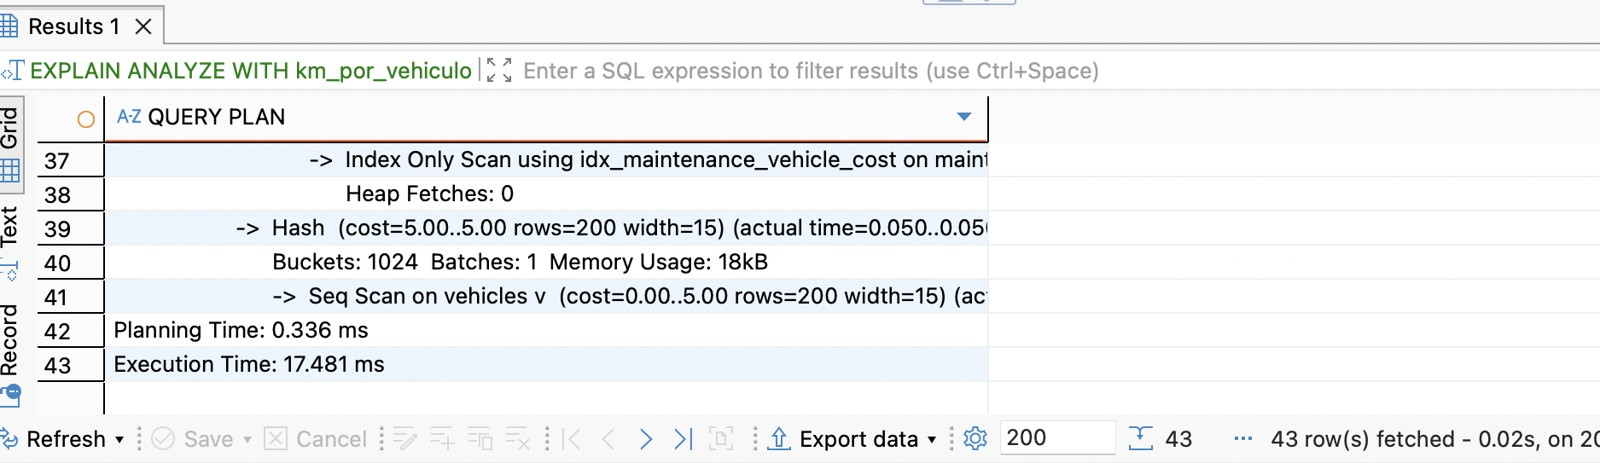

In [51]:
captura("Q9_ajustada_antes"); captura("Q9_ajustada_despues")

**Q12**

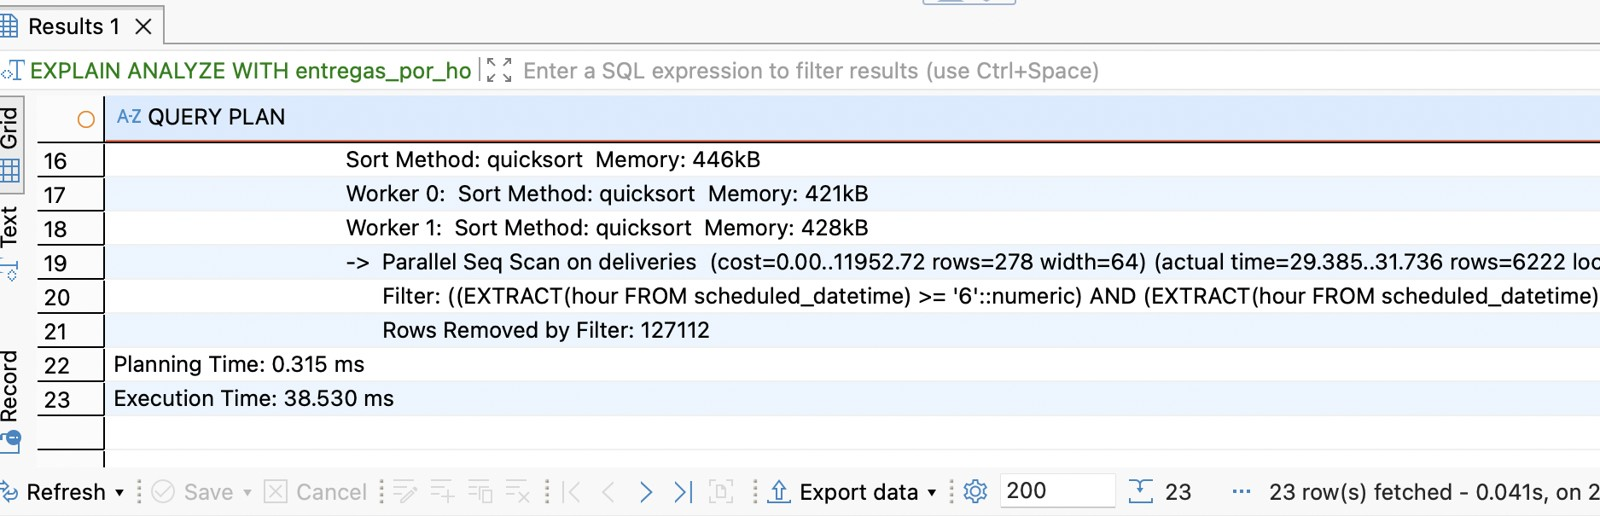

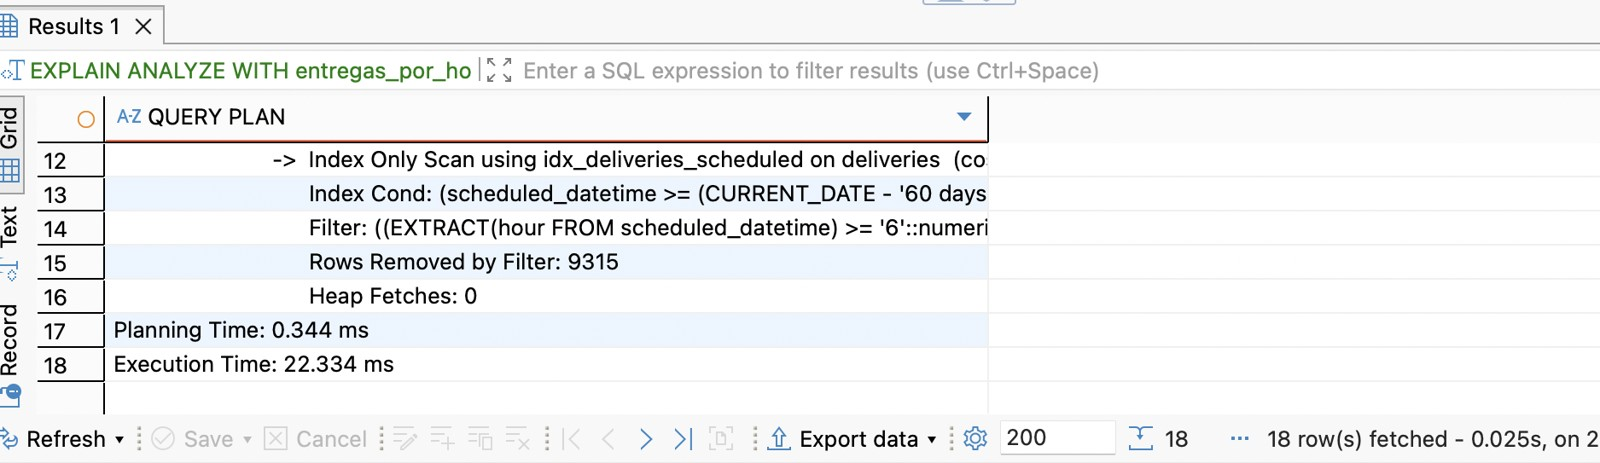

In [52]:
captura("Q12_antes"); captura("Q12_despues")

**Q1, Q2 y Q5** (sin mejora esperada)

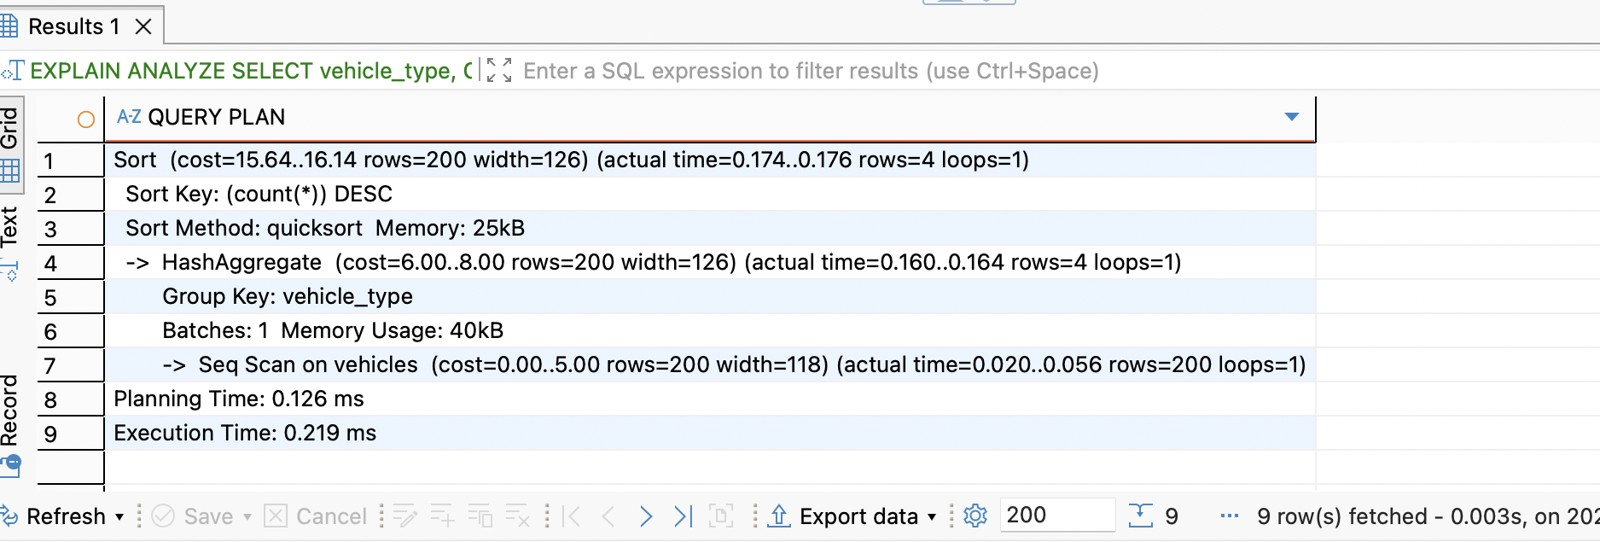

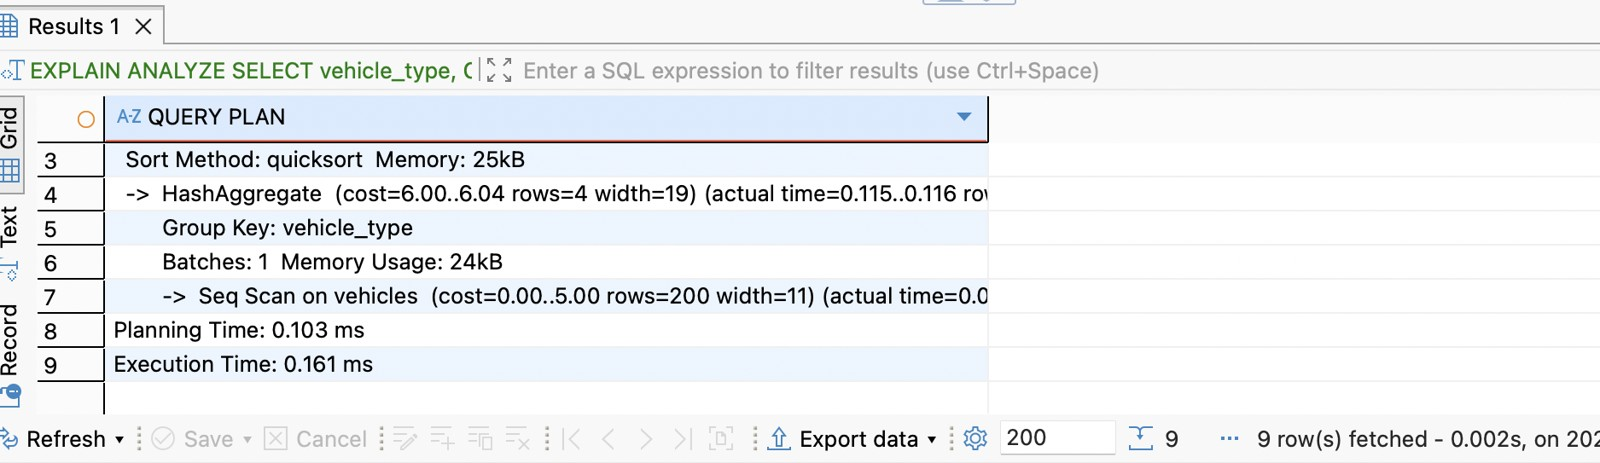

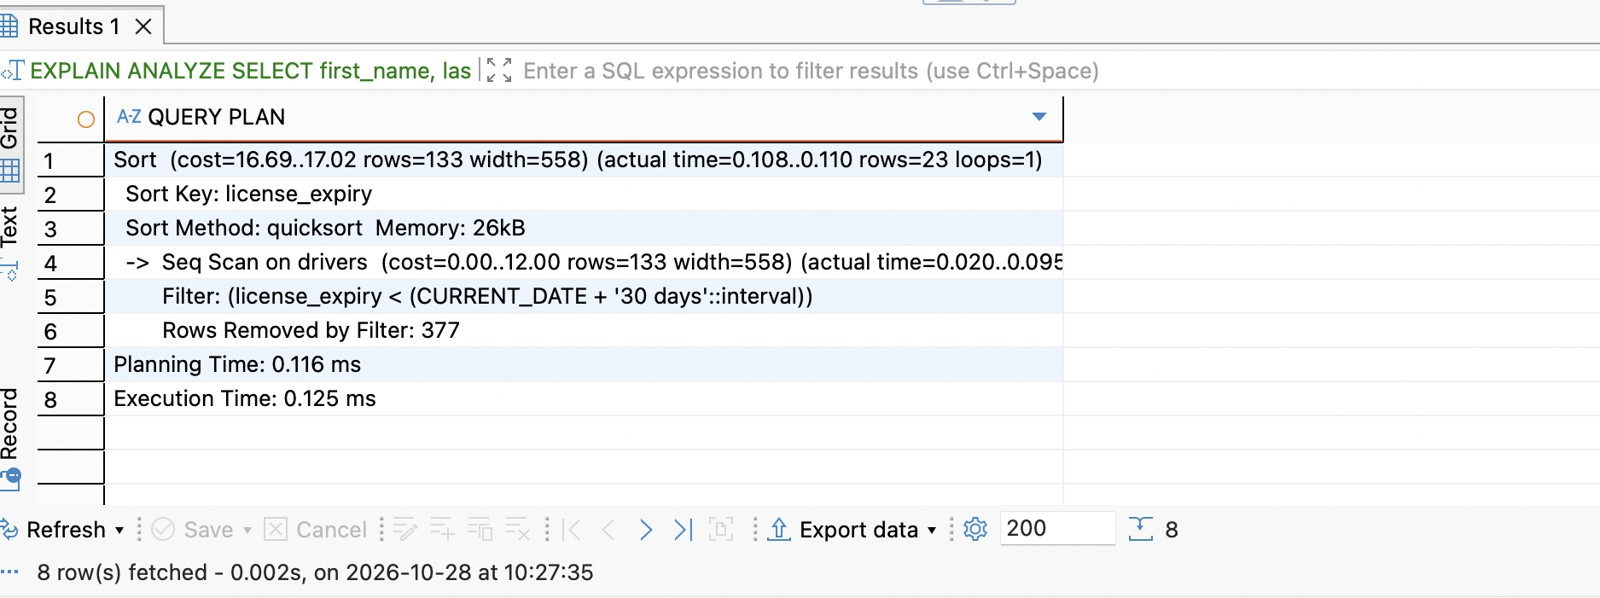

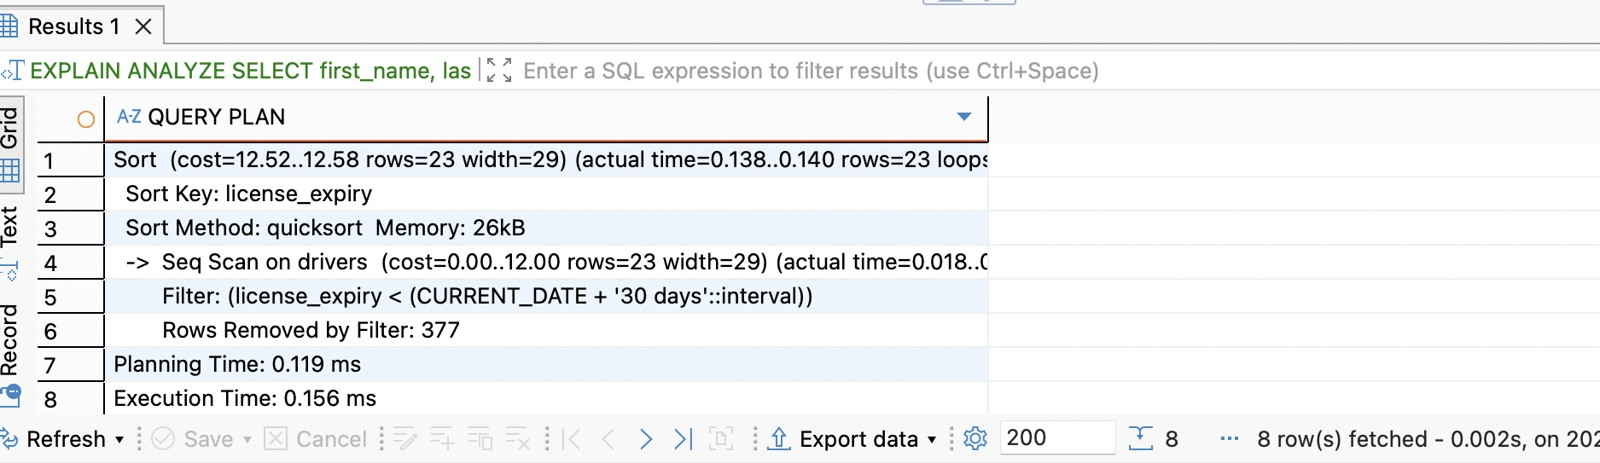

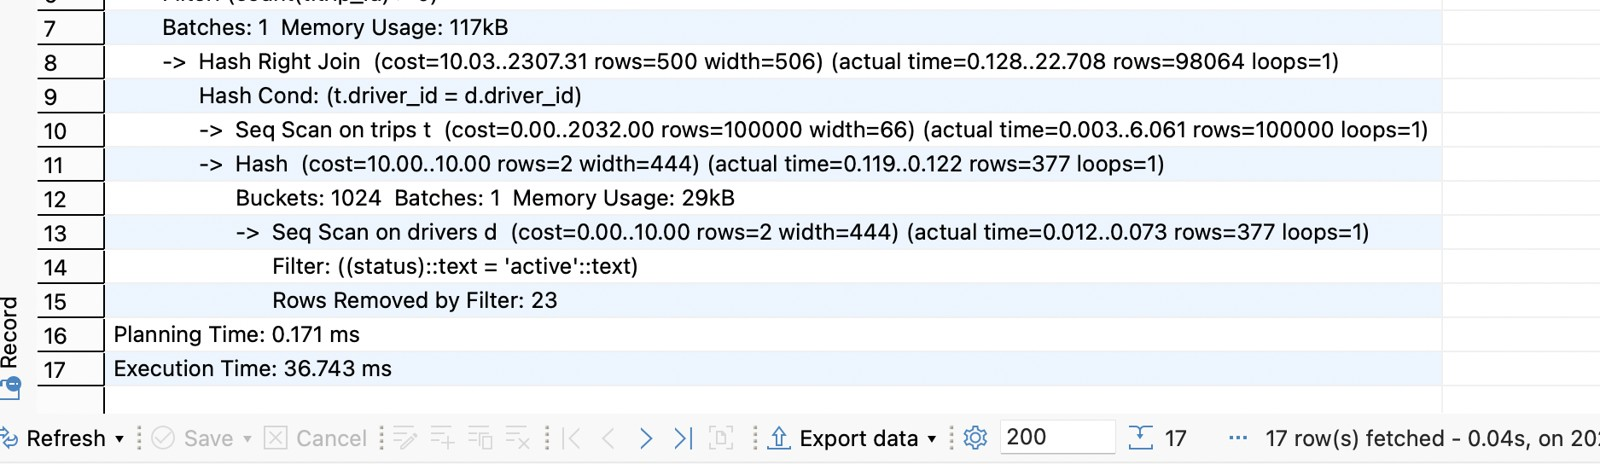

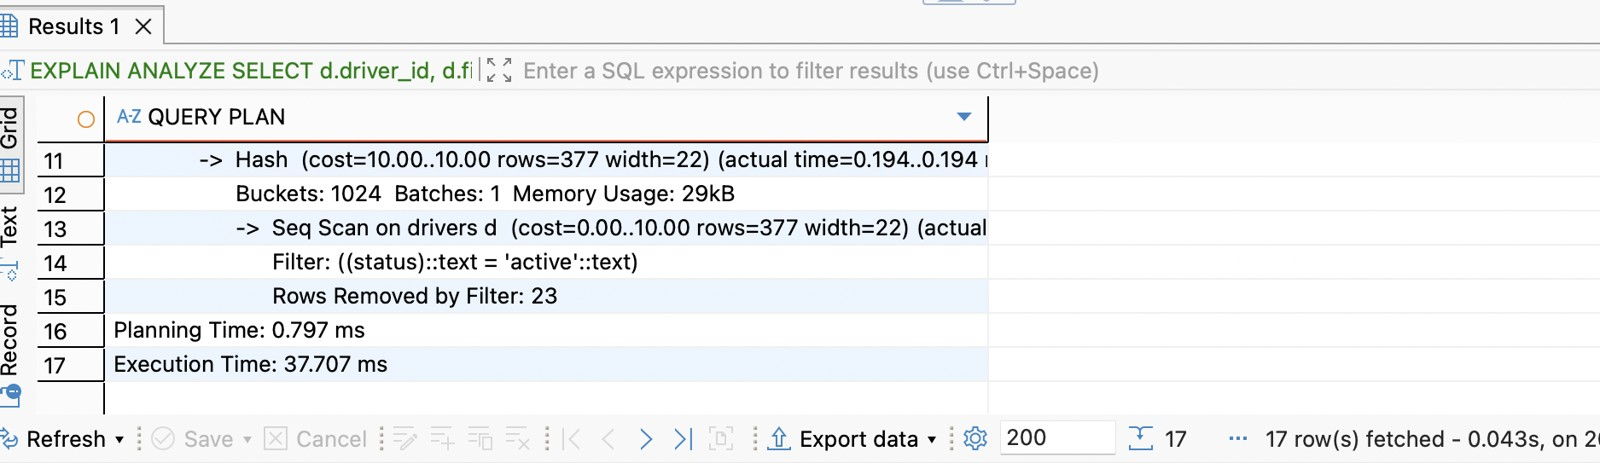

In [53]:
for n in ["Q1", "Q2", "Q5"]:
    captura(f"{n}_antes", 700); captura(f"{n}_despues", 700)

**Índices creados**

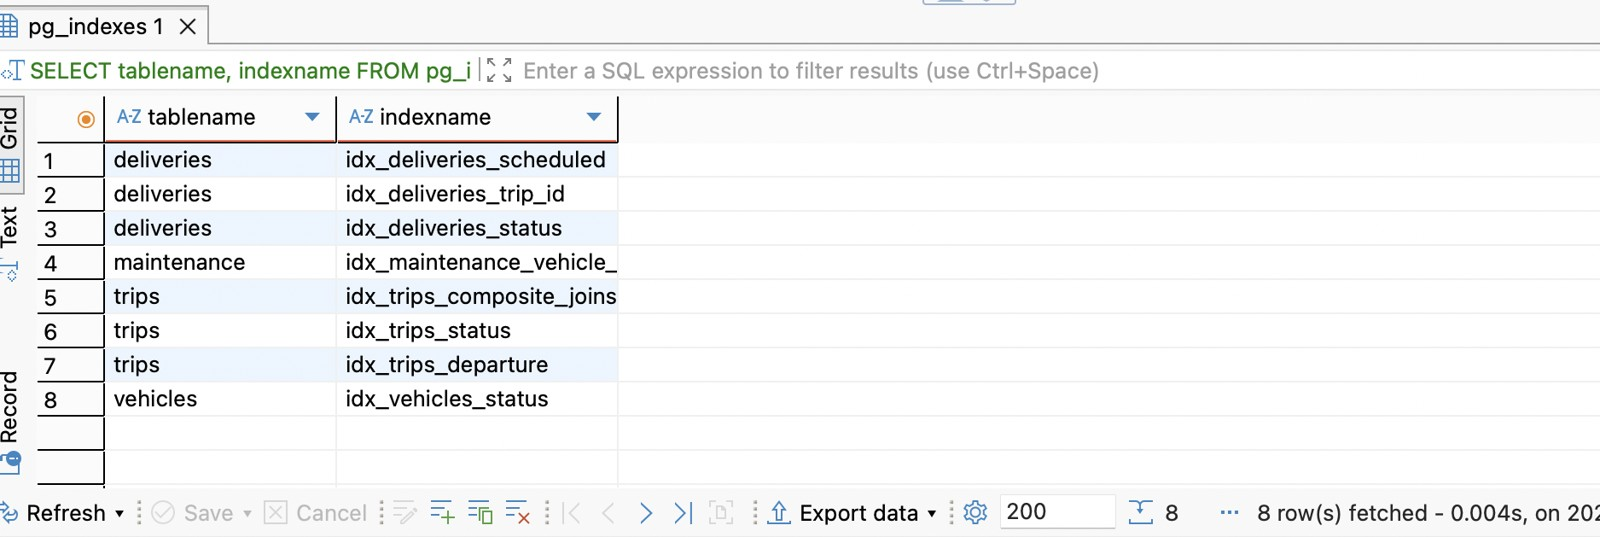

In [54]:
captura("indices_creados")

In [55]:
conn.close()

## 7. Conclusiones

- **8 queries ejecutadas y documentadas**, cada una con su problema de negocio, resultado y análisis. Varias necesitaron una segunda query de verificación para interpretarse bien (Q4, Q5, Q9).
- **Hallazgos de negocio:**
  - 14 de las 23 licencias de la Q2 ya están vencidas.
  - La diferencia de viajes entre conductores se explica por antigüedad.
  - El retraso de las entregas es estructural (~12-15% todos los días).
  - La moto es el vehículo más caro de mantener por kilómetro.
  - El domingo a la mañana requiere personal aunque casi no haya despachos.
- **En la Q9 se ajustó la agregación:** la versión inicial combinaba viajes y mantenimientos en el mismo JOIN, multiplicaba filas y sobrestimaba los costos ~600 veces. Se detectó contrastando con la suma directa de la tabla.
- **Optimización:**
  - De los 5 índices propuestos, se conservaron los 2 que se usaban y se sumaron 3 nuevos, elegidos a partir de las mediciones.
  - Las queries sobre `deliveries` y la Q9 ajustada mejoran entre 42% y 54%.
  - Ajustar la lógica de la Q9 y luego indexarla llevó su tiempo de 802 a 17 ms (**98%**).
- **No todo mejora con índices,** y explicarlo también es un resultado: las tablas chicas ya son instantáneas, y las queries que leen toda la tabla no se benefician.